# Coffee Vending Machine Sales: Exploratory Data Analysis

## tl;dr

This notebook reviews CSV1 only: 3,636 transaction records from March 1, 2024 through March 23, 2025. The file records sales amount, drink, payment type, and timestamp; the currency is not documented. Latte leads recorded sales (27,866.30 source units), while Americano with Milk has the most transaction records (824). Transactions peak at 10:00 (349 records). The timing patterns can inform when an operator schedules routine machine checks. The file has no inventory or stockout data and cannot establish lost demand or exact reorder quantities.

**Decision-maker:** vending-machine operator.
**Decision supported:** schedule routine replenishment checks before observed demand peaks, and investigate unusually low weekly transaction counts before changing the schedule.
**Source:** Kaggle, [Coffee Sales](https://www.kaggle.com/datasets/ihelon/coffee-sales), CSV1 (`index_1.csv`), downloaded version 21 (March 25, 2025).

## Context & Methods

The observation unit is one row in the transaction log. EDA covers the full CSV1 file without joining another file. Date and timestamp fields are parsed as datetimes; money is treated as a recorded amount in unspecified source units. Missing card identifiers are retained because the transaction itself has other observed fields.

### Key assumptions
- A row represents one recorded sale, consistent with the dataset description; there is no separate order ID to independently verify this grain.
- Calendar dates without rows are treated as dates without recorded transactions, not proven zero-demand days.
- The dataset is a static snapshot ending March 23, 2025; it does not support current operational claims.

## Data

### 1. Load and inspect the CSV1 file

In [19]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = Path("index_1.csv")
if not DATA_PATH.exists():
    DATA_PATH = Path("data/index_1.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Place CSV1 (index_1.csv) in the project folder.")

df = pd.read_csv(DATA_PATH, parse_dates=["date", "datetime"])
df.head()

,date,datetime,cash_type,card,money,coffee_name
0,2024-03-01,2024-03-01 10:15:50.520,card,ANON-0000-0000-0001,38.7,Latte
1,2024-03-01,2024-03-01 12:19:22.539,card,ANON-0000-0000-0002,38.7,Hot Chocolate
2,2024-03-01,2024-03-01 12:20:18.089,card,ANON-0000-0000-0002,38.7,Hot Chocolate
3,2024-03-01,2024-03-01 13:46:33.006,card,ANON-0000-0000-0003,28.9,Americano
4,2024-03-01,2024-03-01 13:48:14.626,card,ANON-0000-0000-0004,38.7,Latte


### 2. Check structure, types, missingness, and duplicates

In [20]:
overview = pd.DataFrame({
    "rows": [len(df)],
    "columns": [df.shape[1]],
    "date_start": [df["date"].min().date()],
    "date_end": [df["date"].max().date()],
    "distinct_calendar_dates": [df["date"].dt.date.nunique()],
    "duplicate_rows": [int(df.duplicated().sum())],
    "duplicate_timestamps": [int(df["datetime"].duplicated().sum())],
})
display(overview)
display(pd.DataFrame({"dtype": df.dtypes.astype(str), "missing": df.isna().sum()}))
display(df["cash_type"].value_counts(dropna=False).rename_axis("cash_type").to_frame("records"))

,rows,columns,date_start,date_end,distinct_calendar_dates,duplicate_rows,duplicate_timestamps
0,3636,6,2024-03-01,2025-03-23,381,0,0


,dtype,missing
date,datetime64[us],0
datetime,datetime64[us],0
cash_type,str,0
card,str,89
money,float64,0
coffee_name,str,0


,records
cash_type,
card,3547
cash,89


There are 3,636 rows and no exact duplicate rows or duplicate timestamps. The `card` field is missing for some rows, but those rows still have a payment type, amount, drink, and timestamp. It is not needed for this operational dashboard, so customer-level analysis is excluded. There are 381 observed calendar dates across a 388-day span; the seven dates without rows may be no-sale dates or collection gaps.

## Results

### 3. Sales amount and drink mix

In [21]:
sales_summary = pd.Series({
    "Transaction records": len(df),
    "Total recorded sales (source units)": df["money"].sum(),
    "Mean amount per record (source units)": df["money"].mean(),
    "Median amount per record (source units)": df["money"].median(),
    "Unique drinks": df["coffee_name"].nunique(),
})
display(sales_summary.to_frame("value").round(2))

drink_summary = (
    df.groupby("coffee_name", as_index=False)
      .agg(transaction_records=("money", "size"), recorded_sales=("money", "sum"))
      .sort_values("transaction_records", ascending=False)
)
drink_summary["transaction_share_pct"] = drink_summary["transaction_records"] / len(df) * 100
drink_summary["sales_share_pct"] = drink_summary["recorded_sales"] / df["money"].sum() * 100
display(drink_summary.round(2))

,value
Transaction records,3636.00
Total recorded sales (source units),115431.58
Mean amount per record (source units),31.75
Median amount per record (source units),32.82
Unique drinks,8.00


,coffee_name,transaction_records,recorded_sales,transaction_share_pct,sales_share_pct
1,Americano with Milk,824,25269.12,22.66,21.89
7,Latte,782,27866.30,21.51,24.14
0,Americano,578,15062.26,15.90,13.05
2,Cappuccino,501,18034.14,13.78,15.62
4,Cortado,292,7534.86,8.03,6.53
6,Hot Chocolate,282,10172.46,7.76,8.81
3,Cocoa,243,8678.16,6.68,7.52
5,Espresso,134,2814.28,3.69,2.44


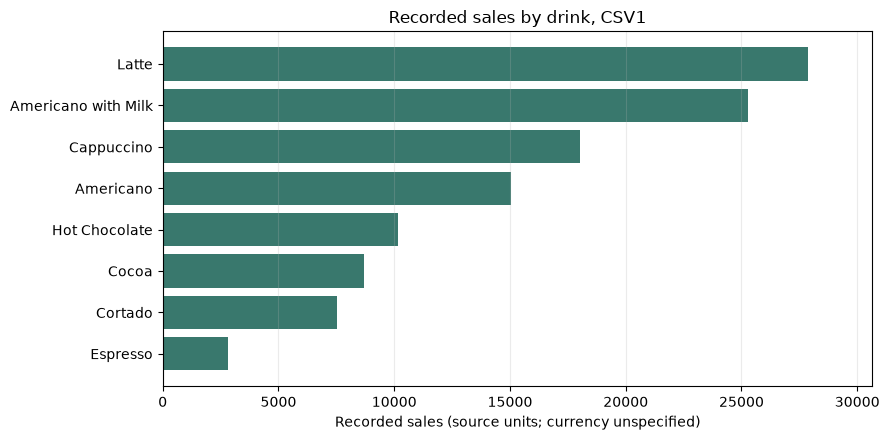

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_data = drink_summary.sort_values("recorded_sales")
ax.barh(plot_data["coffee_name"], plot_data["recorded_sales"], color="#39786d")
ax.set_title("Recorded sales by drink, CSV1")
ax.set_xlabel("Recorded sales (source units; currency unspecified)")
ax.set_ylabel("")
ax.set_xlim(0, plot_data["recorded_sales"].max() * 1.1)
ax.grid(axis="x", alpha=0.25)
fig.tight_layout()
plt.show()

Latte has the highest recorded sales (27,866.30 source units); Americano with Milk has the highest transaction count (824, or about 22.7%). These measures answer different questions, so the dashboard should distinguish sales amount from transaction volume.

### 4. Timing patterns

,transaction_records,recorded_sales,observed_dates
month,,,
2024-03-01,206,7050.20,31
2024-04-01,196,6720.56,30
2024-05-01,267,9063.42,28
2024-06-01,227,7758.76,30
2024-07-01,237,6915.94,31
2024-08-01,272,7613.84,31
2024-09-01,344,9988.64,30
2024-10-01,426,13891.16,31
2024-11-01,259,8590.54,29


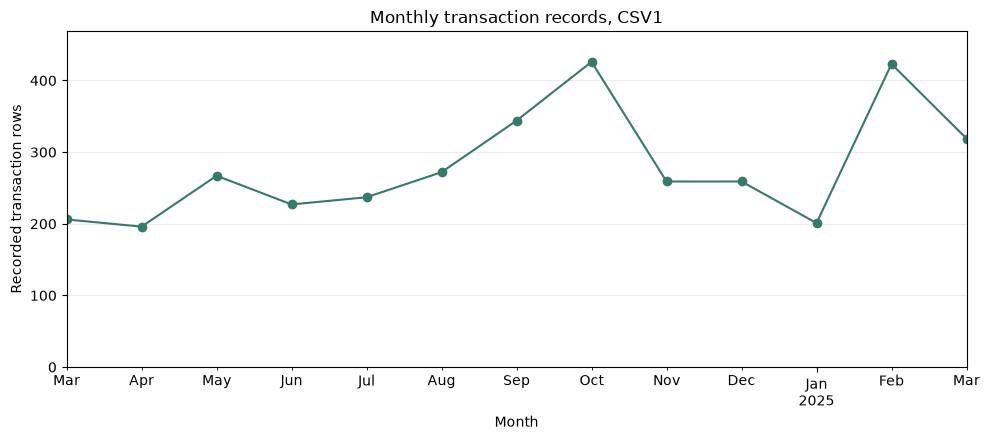

In [23]:
df["month"] = df["datetime"].dt.to_period("M").dt.to_timestamp()
monthly = df.groupby("month").agg(
    transaction_records=("money", "size"),
    recorded_sales=("money", "sum"),
    observed_dates=("date", "nunique"),
)
display(monthly.round(2))

fig, ax = plt.subplots(figsize=(10, 4.5))
monthly["transaction_records"].plot(ax=ax, marker="o", color="#39786d")
ax.set_title("Monthly transaction records, CSV1")
ax.set_xlabel("Month")
ax.set_ylabel("Recorded transaction rows")
ax.set_ylim(0, monthly["transaction_records"].max() * 1.1)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

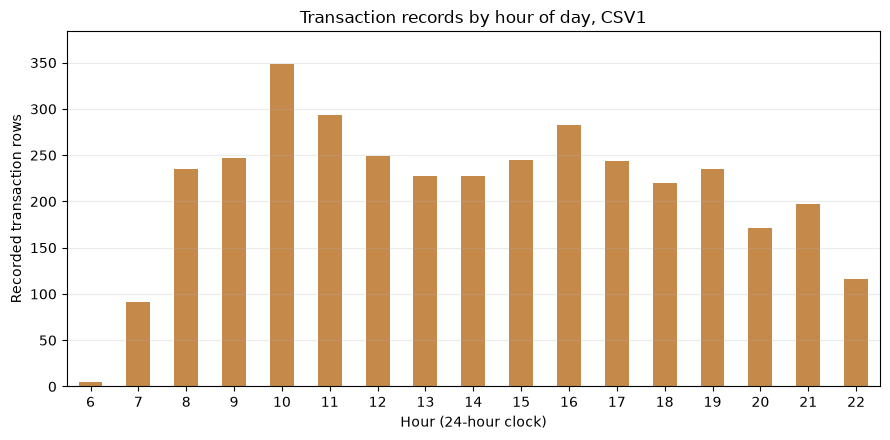

Peak observed hour: 10:00 (349 records)


In [24]:
df["hour"] = df["datetime"].dt.hour
hourly = df.groupby("hour").size().reindex(range(6, 23), fill_value=0)
fig, ax = plt.subplots(figsize=(9, 4.5))
hourly.plot.bar(ax=ax, color="#c58a4a")
ax.set_title("Transaction records by hour of day, CSV1")
ax.set_xlabel("Hour (24-hour clock)")
ax.set_ylabel("Recorded transaction rows")
ax.set_ylim(0, hourly.max() * 1.1)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()
print(f"Peak observed hour: {int(hourly.idxmax()):02d}:00 ({int(hourly.max())} records)")

The highest hour is 10:00, with 349 records; 11:00 is next with 294. This supports scheduling a machine check before the morning peak as a testable operational hypothesis. Monthly counts vary substantially, but the final month is partial (March 2025 ends on March 23), and the seven no-record dates make the trend unsuitable as a clean measure of daily demand without checking source completeness.

## Takeaways

1. **Use three headline metrics:** transaction-record count, average records per observed transaction day, and recorded sales amount. Label money in source units because the source does not document currency.
2. **Keep two supporting views:** a weekly transaction trend for monitoring the operating pattern and an hourly transaction chart to inform the timing of replenishment checks.
3. **Use practical filters only:** date range and drink. The card identifier is unnecessary for this decision and can be omitted from the app.
4. **State the limits beside the charts:** seven calendar dates have no rows; these may represent no transactions or collection gaps. March 2025 is partial. No inventory, stockout, waste, or cost records are available.
5. **Production proposal:** refresh from the vending machine sales log nightly and review weekly. A proposed review trigger flags a complete week whose transaction-record count is at least 20% below the preceding eight-week average. It prompts an uptime and data-capture check before changing the replenishment plan; treat 20% as a starting threshold and calibrate it against operational logs.

The snapshot is historical. In production, an operator should use a current feed and pair sales with inventory and replenishment records before setting quantities.